# Очистка данных

Сохраняем объявления с аномалиями и заменяем сомнительные цены и даты пропусками. Отдельные CSV с исходными выбросами оставляем для анализа.

### Загрузка данных

In [224]:
from pathlib import Path

import pandas as pd

df = pd.read_csv("data/listings.csv").drop_duplicates()
assert df["listing_id"].is_unique

display(df.shape)
df.head()

(15274, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
0,132065,31904,private,Одежда и обувь,Пуховик женский б/у,570,470,3,130.0,Москва,2026-09-07 19:40:26,2026-09-22 11:05:13,снято продавцом,193,10,0,4,21
1,131440,31664,private,Одежда и обувь,Рюкзак городской с документами,0,0,3,39.0,Санкт-Петербург,2026-09-07 09:55:11,2026-09-11 20:55:35,снято продавцом,21,2,0,0,0
2,117997,24387,private,Мебель и интерьер,Комод,2080,2080,6,128.0,СПб,2026-08-22 18:11:20,2026-09-06 17:09:12,снято продавцом,140,6,1,4,25
3,129810,20372,private,Одежда и обувь,Пуховик женский б/у,1320,1320,8,202.0,Москва,2026-09-05 16:07:34,2026-09-08 15:10:57,снято продавцом,50,1,0,4,23
4,111780,13149,private,Спорт и отдых,Спальный мешок,5030,5030,3,82.0,Санкт-Петербург,2026-08-15 14:31:56,2026-09-14 14:31:56,истёк срок,245,9,2,10,44


### Заменяем противоречивые даты пропусками

In [ ]:
date_columns = ["published_at", "closed_at"]
df[date_columns] = df[date_columns].apply(pd.to_datetime, errors="coerce")

bad_time = (
    df[date_columns].isna().any(axis=1)
    | (df["published_at"] >= df["closed_at"])
)
listing_ids_of_bad_time = df.loc[bad_time, "listing_id"]
df.loc[bad_time, date_columns] = pd.NaT

print("Объявлений с пропусками в датах:", bad_time.sum())

### Посторим графики и посмотрим на данные. Цель - понять, где есть впринципе выбросы и где есть cлишком больших выбросы

##### Смотрим по этим столбцам: 
* price 
* current_price
* photos_count
* description_length
* views_total
* favorites_total
* phone_views_total
* chats_total
* messages_total

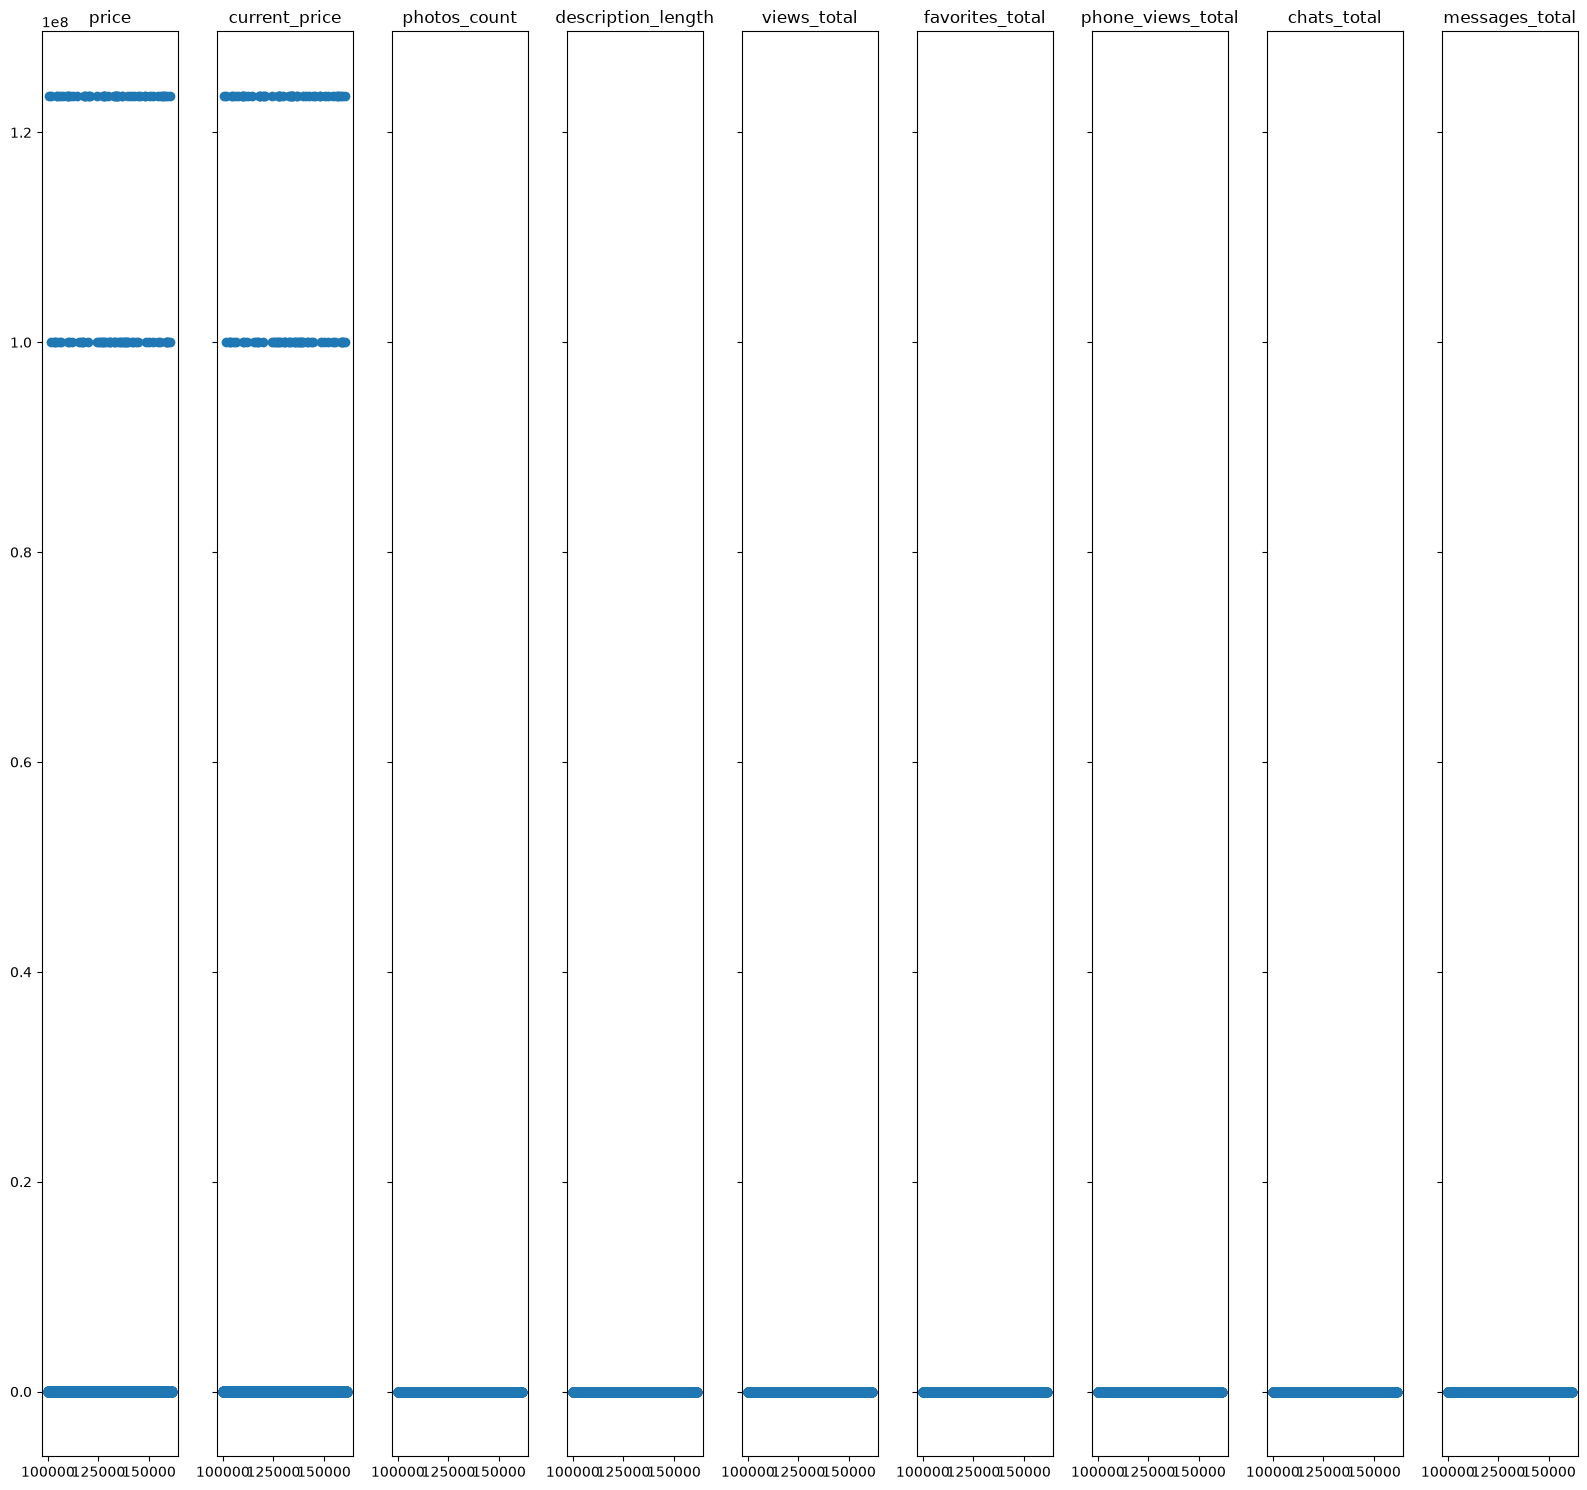

In [225]:
import matplotlib.pyplot as plt

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

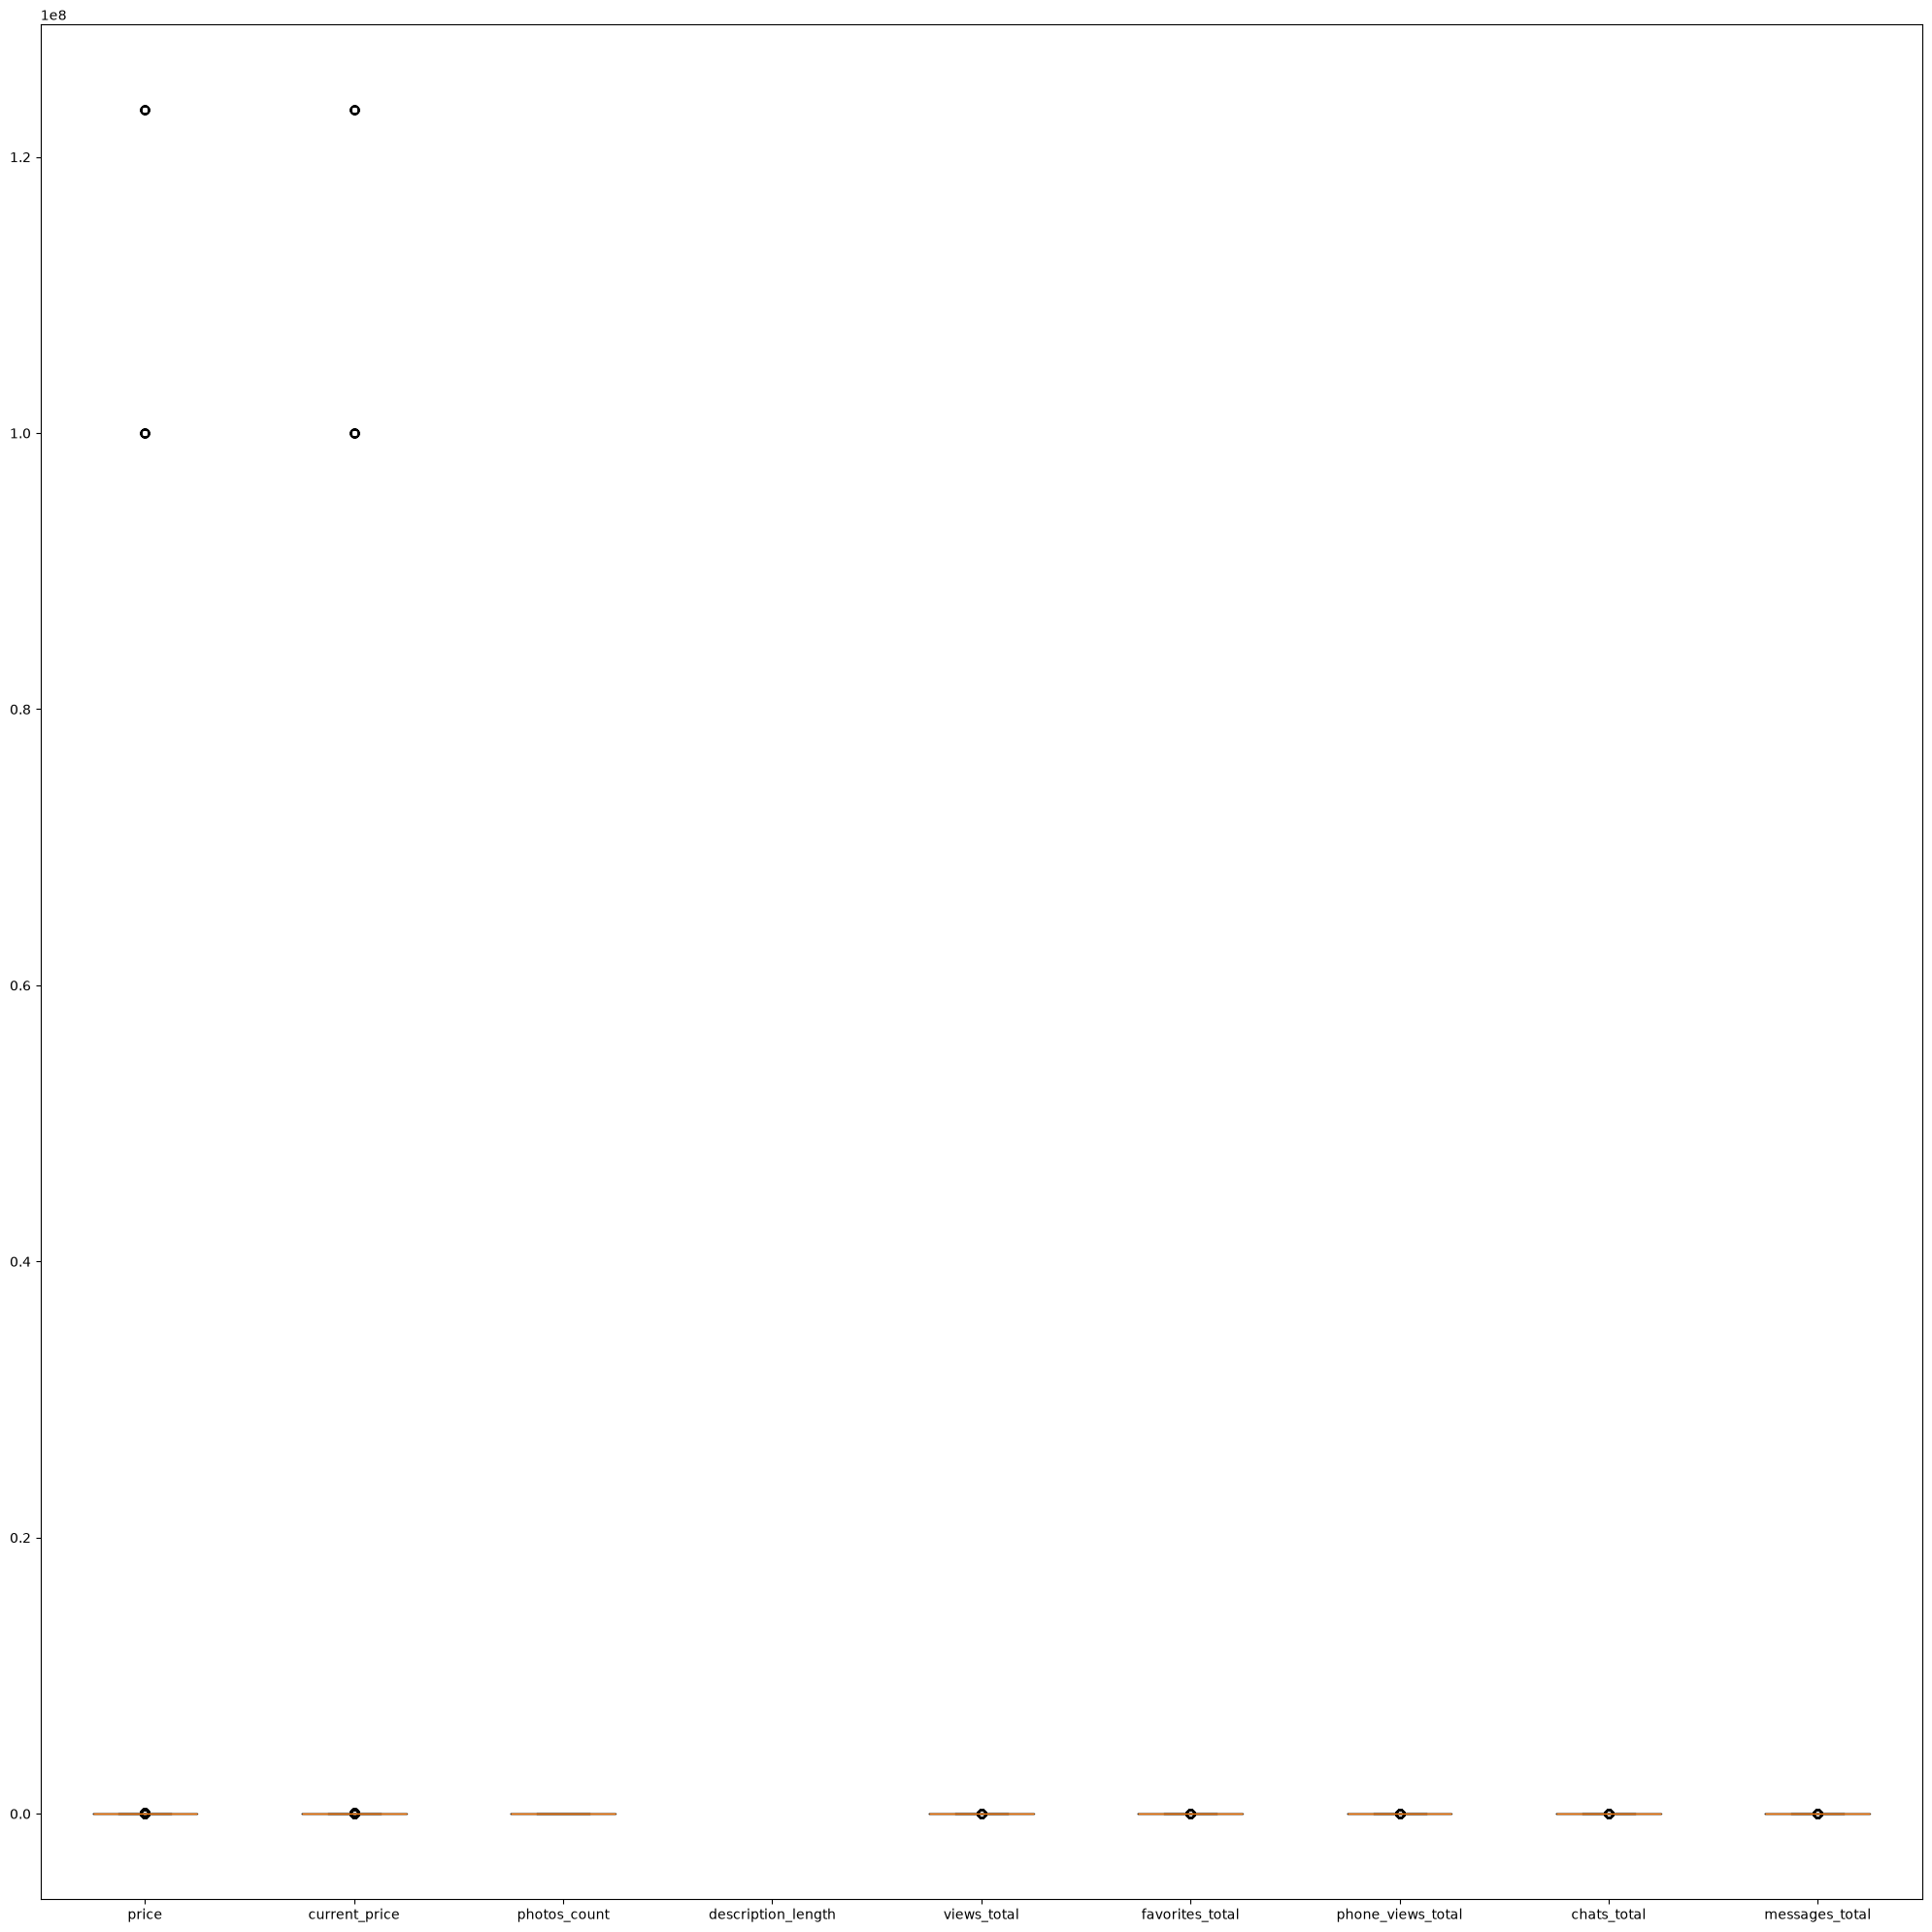

In [226]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 20))
plt.boxplot(data, tick_labels=values)

plt.tight_layout()
plt.show()

### Находим слишком высокие и слишком низкие цены

In [227]:
price_columns = ["price", "current_price"]
high_prices = (df[price_columns] > 20_000_000).any(axis=1)
low_prices = (df[price_columns] < 20).any(axis=1)

indexes_high = df.loc[high_prices, "listing_id"]
low_listing_ids = df.loc[low_prices, "listing_id"]

print("Объявлений с высокими ценами:", high_prices.sum())
print("Объявлений с низкими ценами:", low_prices.sum())

Объявлений с высокими ценами: 98
Объявлений с низкими ценами: 85


### Заменяем аномальные цены пропусками

In [228]:
df.loc[high_prices | low_prices, price_columns] = float("nan")
assert df.loc[high_prices | low_prices, price_columns].isna().all().all()
assert df.loc[bad_time, date_columns].isna().all().all()

display(df[price_columns].describe())

NameError: name 'bad_time' is not defined

### Распределения после очистки

In [ ]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

### Сохраняем объявления, события, сообщения и опросы

Для событий и сообщений проверяем собственное время записи. Если даты объявления известны, оставляем записи между публикацией и закрытием. Если даты противоречат друг другу, сохраняем записи с корректным временем без проверки границ объявления.

In [ ]:
listings_clean = df
output = Path("data/data_wthout_anomailes")
output.mkdir(exist_ok=True)

files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
time_columns = {"events.csv": "event_time", "messages.csv": "sent_at"}

for file in files:
    table = pd.read_csv(f"data/{file}").drop_duplicates()
    before = len(table)

    if file == "listings.csv":
        assert set(listings_clean["listing_id"]) == set(table["listing_id"])
        table = listings_clean
    elif file in time_columns:
        time_column = time_columns[file]
        table[time_column] = pd.to_datetime(table[time_column], errors="coerce")
        checked = table.merge(
            listings_clean[["listing_id", *date_columns]],
            on="listing_id",
            how="inner",
            validate="many_to_one",
        )
        dates_missing = checked["published_at"].isna() | checked["closed_at"].isna()
        within_dates = checked[time_column].between(
            checked["published_at"], checked["closed_at"]
        )
        table = checked.loc[
            checked[time_column].notna() & (dates_missing | within_dates),
            table.columns,
        ]

    table.to_csv(output / f"{file[:-4]}_wthout_anomailes.csv", index=False)
    print(file, before, "→", len(table))

### Собираем единый csv со всеми аномалиями

In [ ]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df_1 = df[df["listing_id"].isin(listing_ids_of_bad_time)]
    df_2 = df[df["listing_id"].isin(low_listing_ids)]
    df_3 = df[df["listing_id"].isin(indexes_high)]
    df = pd.concat([df_1, df_2, df_3])
    df = df.drop_duplicates()
    display(file, df.shape)
    display("--------------------------------------------")
    df.to_csv(f"data/data_ONLY_anomailes/{file[:-4]}_ONLY_anomailes.csv", index=False, encoding="utf-8")

### Собираем отдельный csv по типам аномалий

In [ ]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(low_listing_ids)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_low_listing_ids/{file[:-4]}_anomalies_low_listing_ids.csv", index=False, encoding="utf-8")
    low_listing_ids.to_csv(f"data_temp/low_listing_ids.csv", index=False, encoding="utf-8")

In [ ]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(listing_ids_of_bad_time)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_bad_time/{file[:-4]}_anomalies_bad_time.csv", index=False, encoding="utf-8")
    listing_ids_of_bad_time.to_csv(f"data_temp/listing_ids_of_bad_time.csv", index=False, encoding="utf-8")

In [ ]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    df = df[df["listing_id"].isin(indexes_high)]
    display(file, df.shape)
    df.to_csv(f"data/data_ONLY_anomailes/anomalies_high_listing_ids/{file[:-4]}_anomalies_high_listing_ids.csv", index=False, encoding="utf-8")
    indexes_high.to_csv(f"data_temp/listing_id_of_high.csv", index=False, encoding="utf-8")